# Before and after grocery access

**Emmanuel Sampson · Chicago 2021–2025**

These are shortest-route accessibility estimates around verified events. The model selects the nearest eligible alternative at each date; it does not observe or prescribe shopping choices.

Publication record: Release candidate · 17 November 2026 · v1.0.0. [Website](https://emmanuelsampson-prog.github.io/grocery-access-chicago/) · [Repository](https://github.com/emmanuelsampson-prog/grocery-access-chicago). All maps and charts are generated with Matplotlib.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import geopandas as gpd
from IPython.display import display, Image, Markdown
pd.set_option('display.max_columns', 20)
DATA = ROOT / 'data/processed'
FIG = ROOT / 'outputs/figures'


## 1. Specification
Focal dates use the reviewed physical-event ledger. Other alternatives use USDA authorization intervals. The network is fixed at 1 January 2023. Walking assumes 4.8 km/h. Driving includes directed outbound and return routes. The main catchment is 1.6 km and the connector cap is 300 m. See `src/analysis.py` and the research protocol for the full calculation.

In [2]:
from src.analysis import load_inputs, summarize
tracts, retailers, events = load_inputs()
summary = json.loads((DATA/'analysis_summary.json').read_text())
display(pd.Series({k:summary[k] for k in ['study_period','projection','network_snapshot','walking_speed_kmh','focal_radius_m','max_connector_m']}))

study_period                                        2021–2025
projection           EPSG:26916; NAD83 / UTM zone 16N; metres
network_snapshot                                   2023-01-01
walking_speed_kmh                                         4.8
focal_radius_m                                           1600
max_connector_m                                           300
dtype: object

## 2. Annual geographic context
The citywide maps use straight-line distance to authorized larger grocery outlets, including regional alternatives. This is a separate measure from the routed event results.

,year,city_authorized_larger_addresses,weighted_straight_distance_km,population_weighted_origins_within_800m_pct
0,2021,296,0.675412,70.283458
1,2022,290,0.681634,69.353958
2,2023,281,0.692553,68.632105
3,2024,284,0.692323,68.381088
4,2025,285,0.687370,69.139382


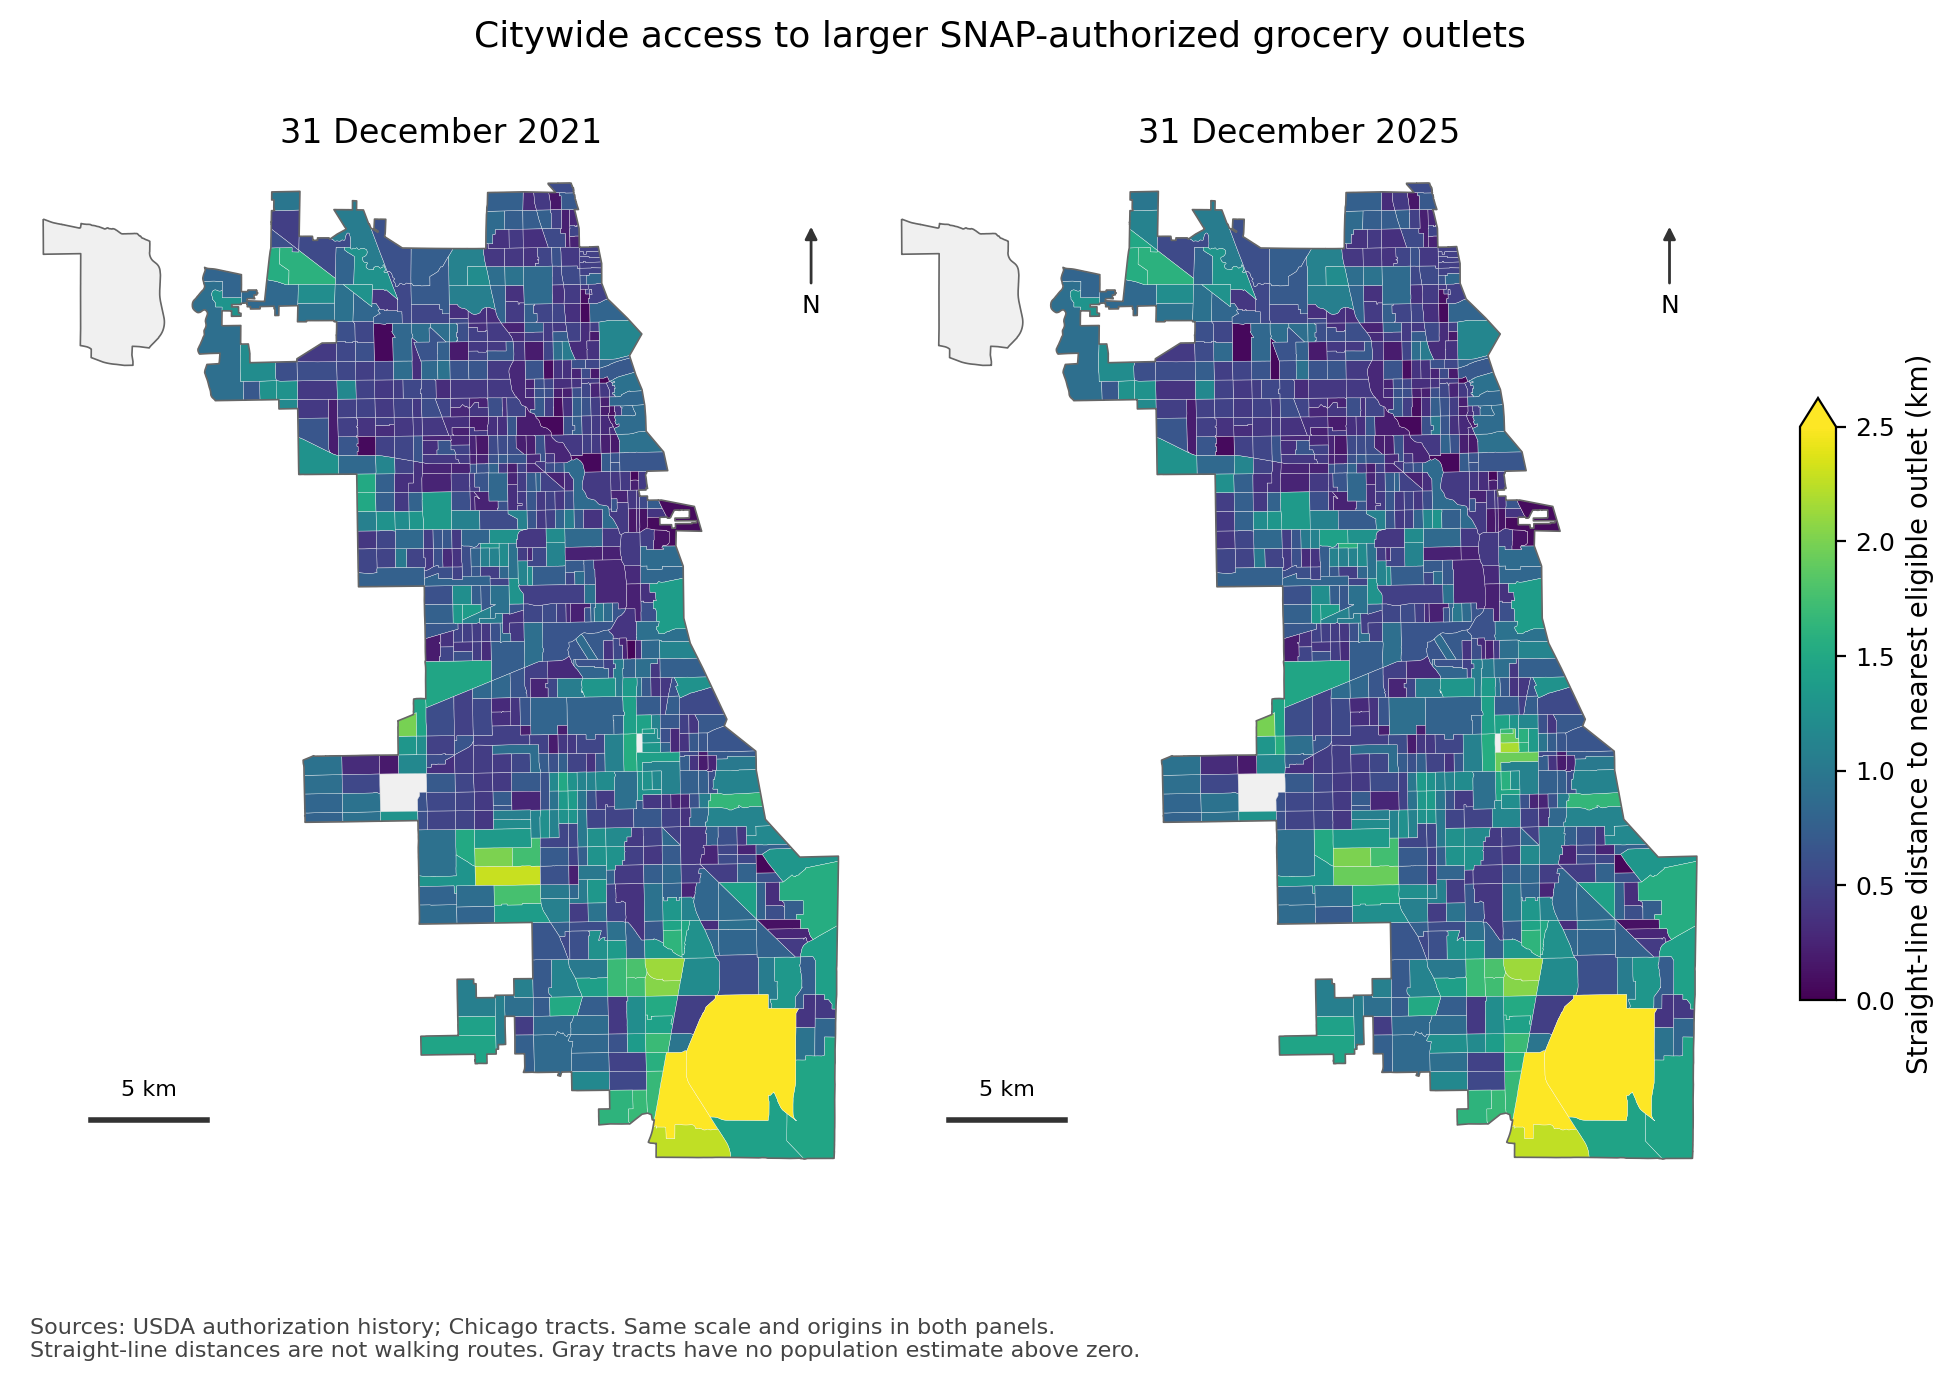

In [3]:
display(pd.read_csv(DATA/'annual_access_context.csv'))
display(Image(filename=str(FIG/'05_citywide_before_after.png')))

## 3. Recalculate event summaries from the origin records

,event_id,included_origins,walk_before_minutes,walk_after_minutes,walk_change_minutes,drive_change_roundtrip_km
0,whole_foods_englewood,14,14.410556,16.506062,2.095507,0.345804
1,walmart_kenwood,22,11.483466,16.098621,4.615155,0.741796
2,walmart_little_village,12,11.045522,11.425288,0.379765,0.144432
3,walmart_chatham,10,15.184523,15.614440,0.429917,0.068787
4,walmart_lakeview,26,9.427377,9.543882,0.116506,0.030959
5,save_a_lot_englewood,14,16.506062,14.410556,-2.095507,-0.345804


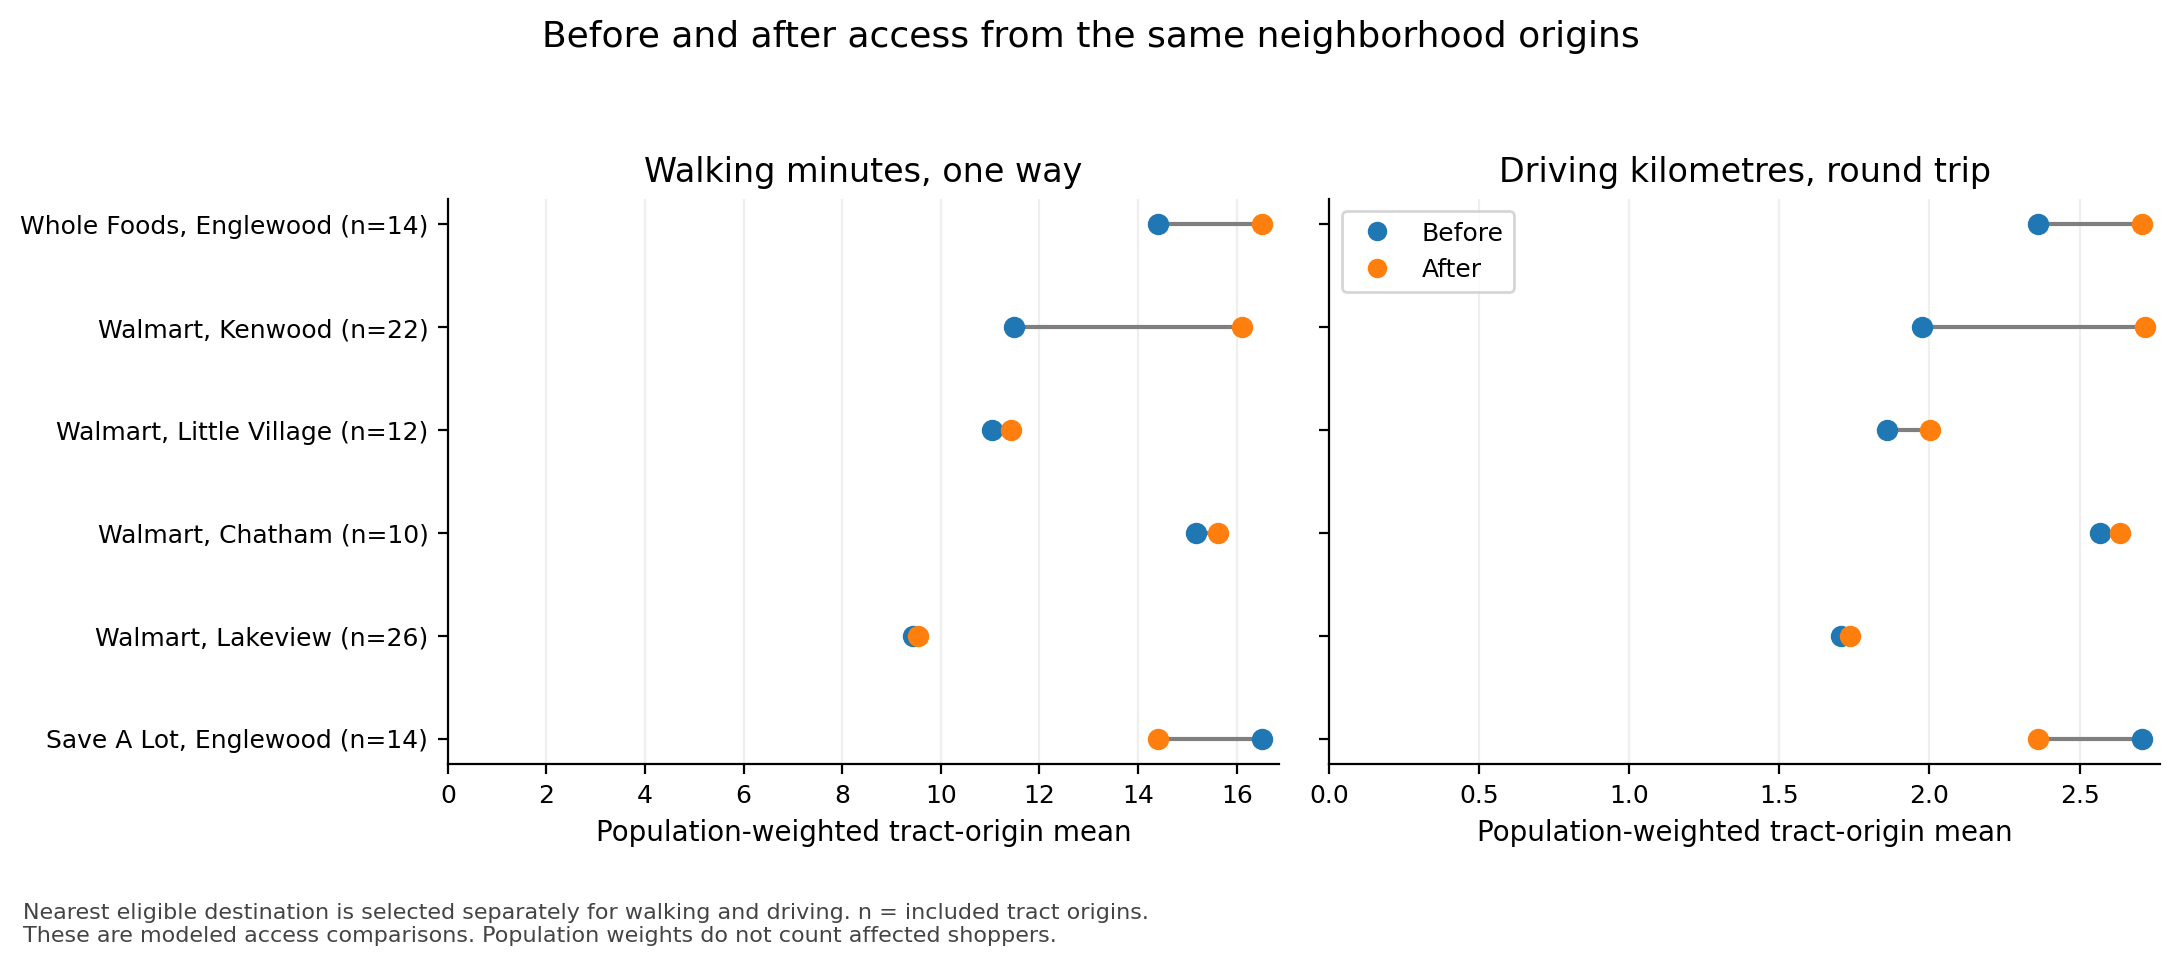

In [4]:
routes = pd.read_csv(DATA/'event_access_origins.csv',dtype={'geoid':str})
main = routes[routes.variant.eq('main')]
recalculated = []
for (period,event), group in main.groupby(['period','event_id'],sort=False):
    recalculated.append(dict(period=period,event_id=event,**summarize(group[group.distance_to_focal_m<=1600])))
recalculated = pd.DataFrame(recalculated)
display(recalculated[['event_id','included_origins','walk_before_minutes','walk_after_minutes','walk_change_minutes','drive_change_roundtrip_km']])
display(Image(filename=str(FIG/'07_paired_event_results.png')))

## 4. Where the changes occur
The same color scale is used in all event panels. Gray areas are outside the included comparison; they are not zero-effect estimates.

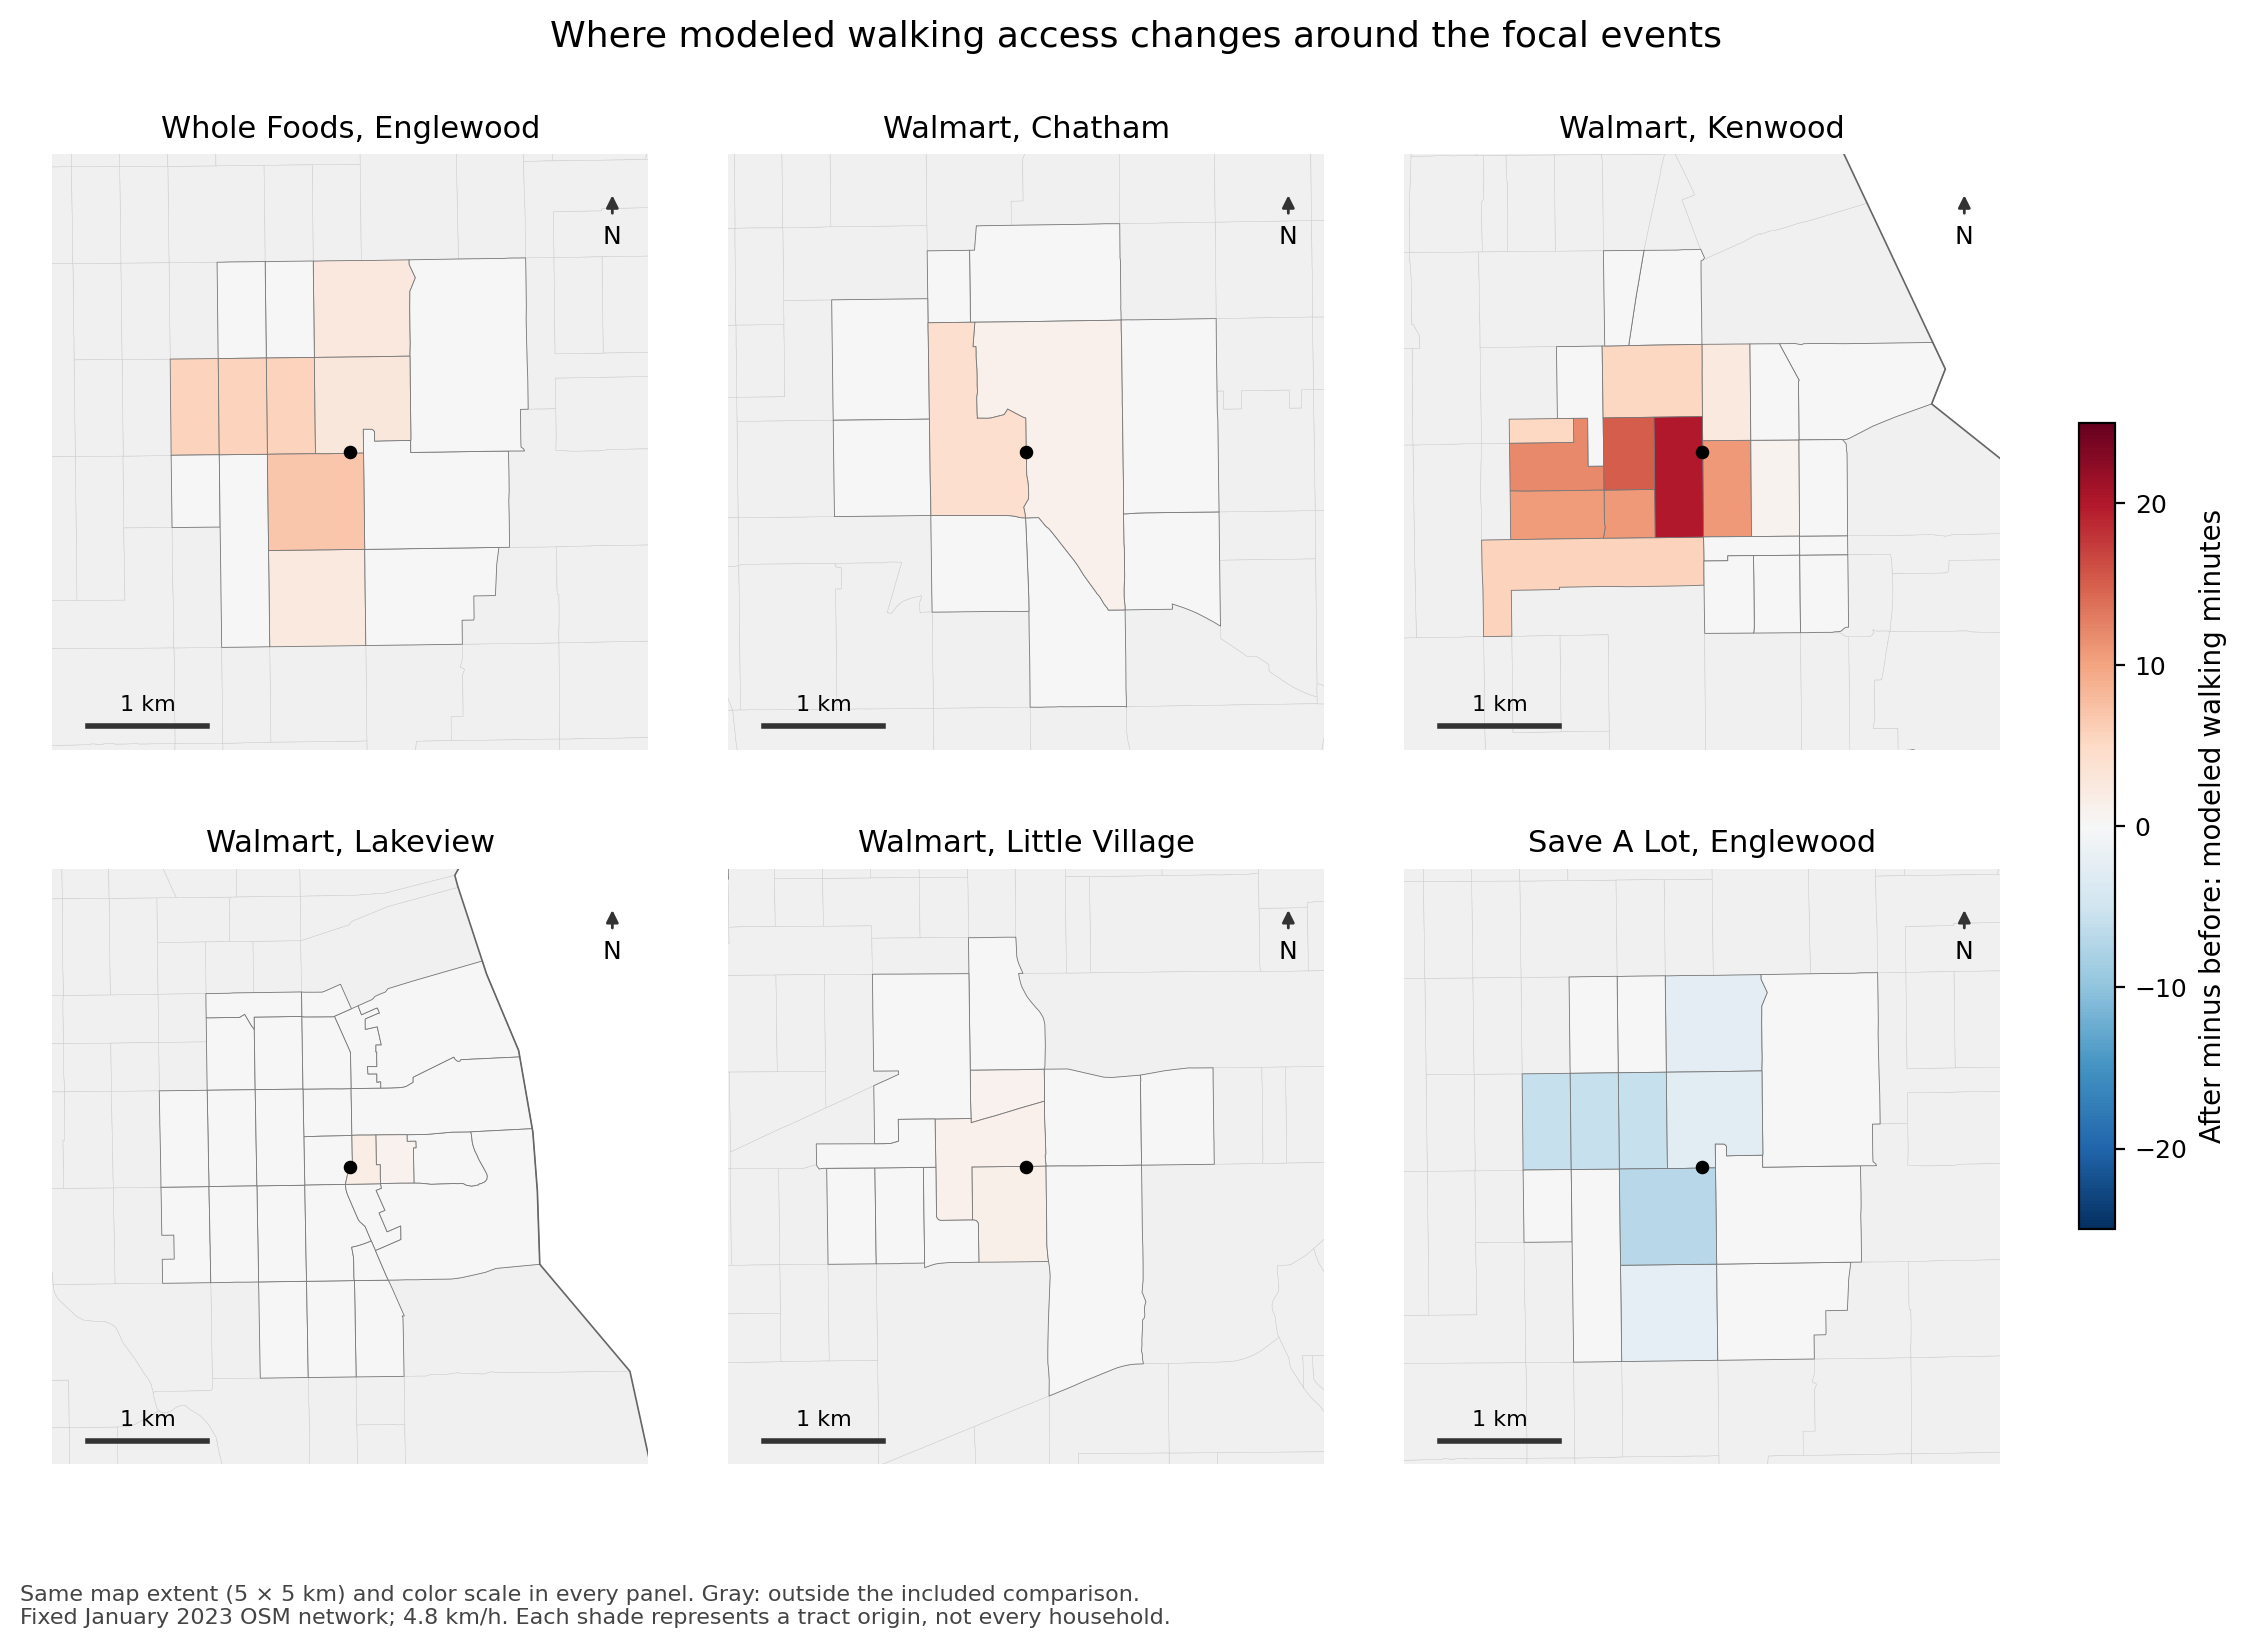

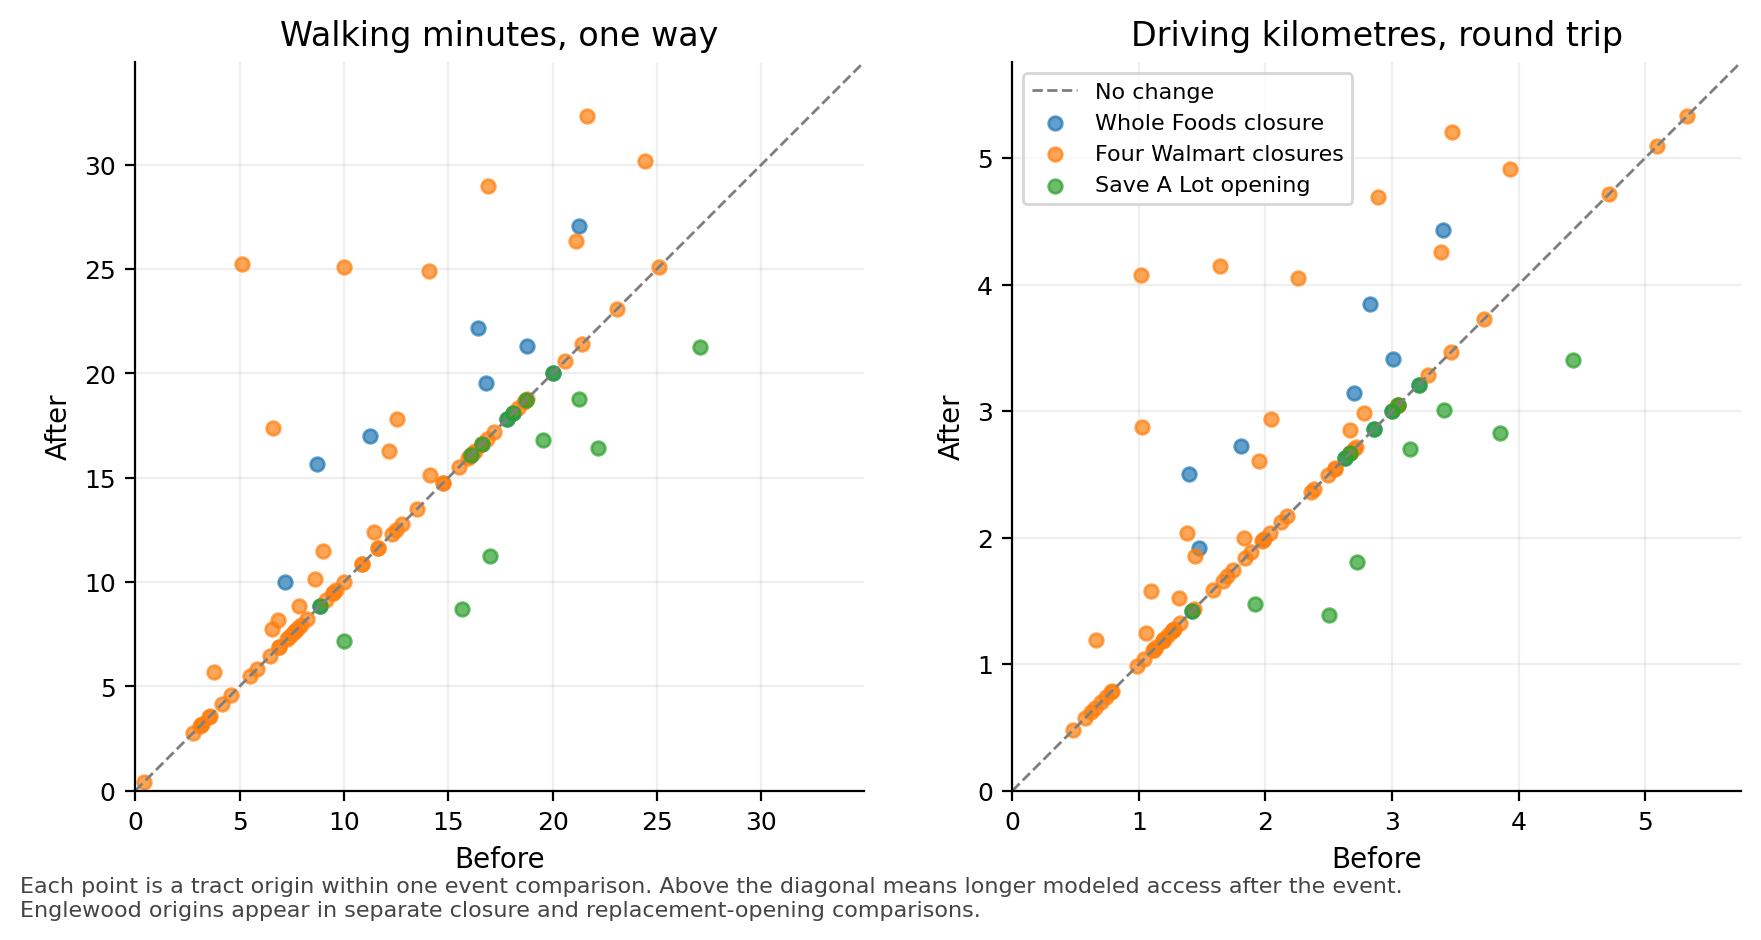

In [5]:
display(Image(filename=str(FIG/'06_event_change_maps.png')))
display(Image(filename=str(FIG/'08_before_after_scatter.png')))

## 5. Equity and sensitivity
These comparisons use pre-event tract characteristics. They do not identify a causal household response. Alternative radii and connector screens are retained. Chatham also has a separate coordinate sensitivity.

,period,group,eligible_origins,included_origins,excluded_origins,tract_population_context,walk_before_minutes,walk_after_minutes,walk_change_minutes,drive_before_roundtrip_km,drive_after_roundtrip_km,drive_change_roundtrip_km,walk_increase_origins,walk_decrease_origins,walk_unchanged_origins,drive_increase_origins,drive_decrease_origins,drive_unchanged_origins,walk_within_15min_before_pct,walk_within_15min_after_pct
0,whole_foods_closure,Poverty below 20%,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,0,NaN,NaN
1,whole_foods_closure,Poverty at least 20%,14,14,0,22340,14.410556,16.506062,2.095507,2.361424,2.707228,0.345804,7,0,7,7,0,7,39.028648,25.147717
2,whole_foods_closure,No vehicle below 30%,3,3,0,4045,16.331955,18.915104,2.583149,2.615007,3.032297,0.417290,2,0,1,2,0,1,24.573548,0.000000
3,whole_foods_closure,No vehicle at least 30%,11,11,0,18295,13.985737,15.973427,1.987690,2.305357,2.635356,0.329999,5,0,6,5,0,6,42.224652,30.707844
4,walmart_closures,Poverty below 20%,41,41,0,126960,10.368821,11.163297,0.794476,1.833270,1.974922,0.141652,8,0,33,9,0,32,74.642407,68.839004
5,walmart_closures,Poverty at least 20%,29,29,0,69826,12.352009,14.312320,1.960311,2.093238,2.444233,0.350995,10,0,19,11,0,18,68.861169,58.082949
6,walmart_closures,No vehicle below 30%,31,31,0,95129,10.929541,12.685989,1.756448,1.870433,2.182296,0.311863,11,0,20,11,0,20,76.205994,63.027047
7,walmart_closures,No vehicle at least 30%,39,39,0,101657,11.206317,11.901382,0.695065,1.977059,2.103224,0.126165,7,0,32,9,0,30,69.208220,66.889639
8,save_a_lot_opening,Poverty below 20%,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,0,NaN,NaN
9,save_a_lot_opening,Poverty at least 20%,14,14,0,22340,16.506062,14.410556,-2.095507,2.707228,2.361424,-0.345804,0,7,7,0,7,7,25.147717,39.028648


,period,radius_m,max_snap_m,eligible_origins,included_origins,excluded_origins,tract_population_context,walk_before_minutes,walk_after_minutes,walk_change_minutes,...,drive_after_roundtrip_km,drive_change_roundtrip_km,walk_increase_origins,walk_decrease_origins,walk_unchanged_origins,drive_increase_origins,drive_decrease_origins,drive_unchanged_origins,walk_within_15min_before_pct,walk_within_15min_after_pct
0,whole_foods_closure,800,100,3,3,0,4838,8.680934,13.900441,5.219508,...,2.338027,0.831632,3,0,0,3,0,0,100.000000,35.903266
1,whole_foods_closure,800,200,3,3,0,4838,8.680934,13.900441,5.219508,...,2.338027,0.831632,3,0,0,3,0,0,100.000000,35.903266
2,whole_foods_closure,800,300,3,3,0,4838,8.680934,13.900441,5.219508,...,2.338027,0.831632,3,0,0,3,0,0,100.000000,35.903266
3,whole_foods_closure,1600,100,14,13,1,21307,14.138019,16.335120,2.197101,...,2.682853,0.362569,7,0,6,7,0,6,40.920824,26.366922
4,whole_foods_closure,1600,200,14,14,0,22340,14.410556,16.506062,2.095507,...,2.707228,0.345804,7,0,7,7,0,7,39.028648,25.147717
5,whole_foods_closure,1600,300,14,14,0,22340,14.410556,16.506062,2.095507,...,2.707228,0.345804,7,0,7,7,0,7,39.028648,25.147717
6,whole_foods_closure,2400,100,33,31,2,49972,15.124111,16.062473,0.938363,...,2.648753,0.159261,8,0,23,8,0,23,44.759065,38.553590
7,whole_foods_closure,2400,200,33,33,0,53334,15.271719,16.150930,0.879211,...,2.658878,0.149222,8,0,25,8,0,25,41.937601,36.123298
8,whole_foods_closure,2400,300,33,33,0,53334,15.271719,16.150930,0.879211,...,2.658878,0.149222,8,0,25,8,0,25,41.937601,36.123298
9,walmart_closures,800,100,20,20,0,60039,7.579656,10.506164,2.926508,...,1.804613,0.538139,13,0,7,13,0,7,100.000000,77.316411


eligible_origins                   10.000000
included_origins                   10.000000
excluded_origins                    0.000000
tract_population_context        29768.000000
walk_before_minutes                14.808607
walk_after_minutes                 15.614440
walk_change_minutes                 0.805833
drive_before_roundtrip_km           2.459428
drive_after_roundtrip_km            2.636033
drive_change_roundtrip_km           0.176605
walk_increase_origins               3.000000
walk_decrease_origins               0.000000
walk_unchanged_origins              7.000000
drive_increase_origins              3.000000
drive_decrease_origins              0.000000
drive_unchanged_origins             7.000000
walk_within_15min_before_pct       28.513840
walk_within_15min_after_pct        21.022575
dtype: float64

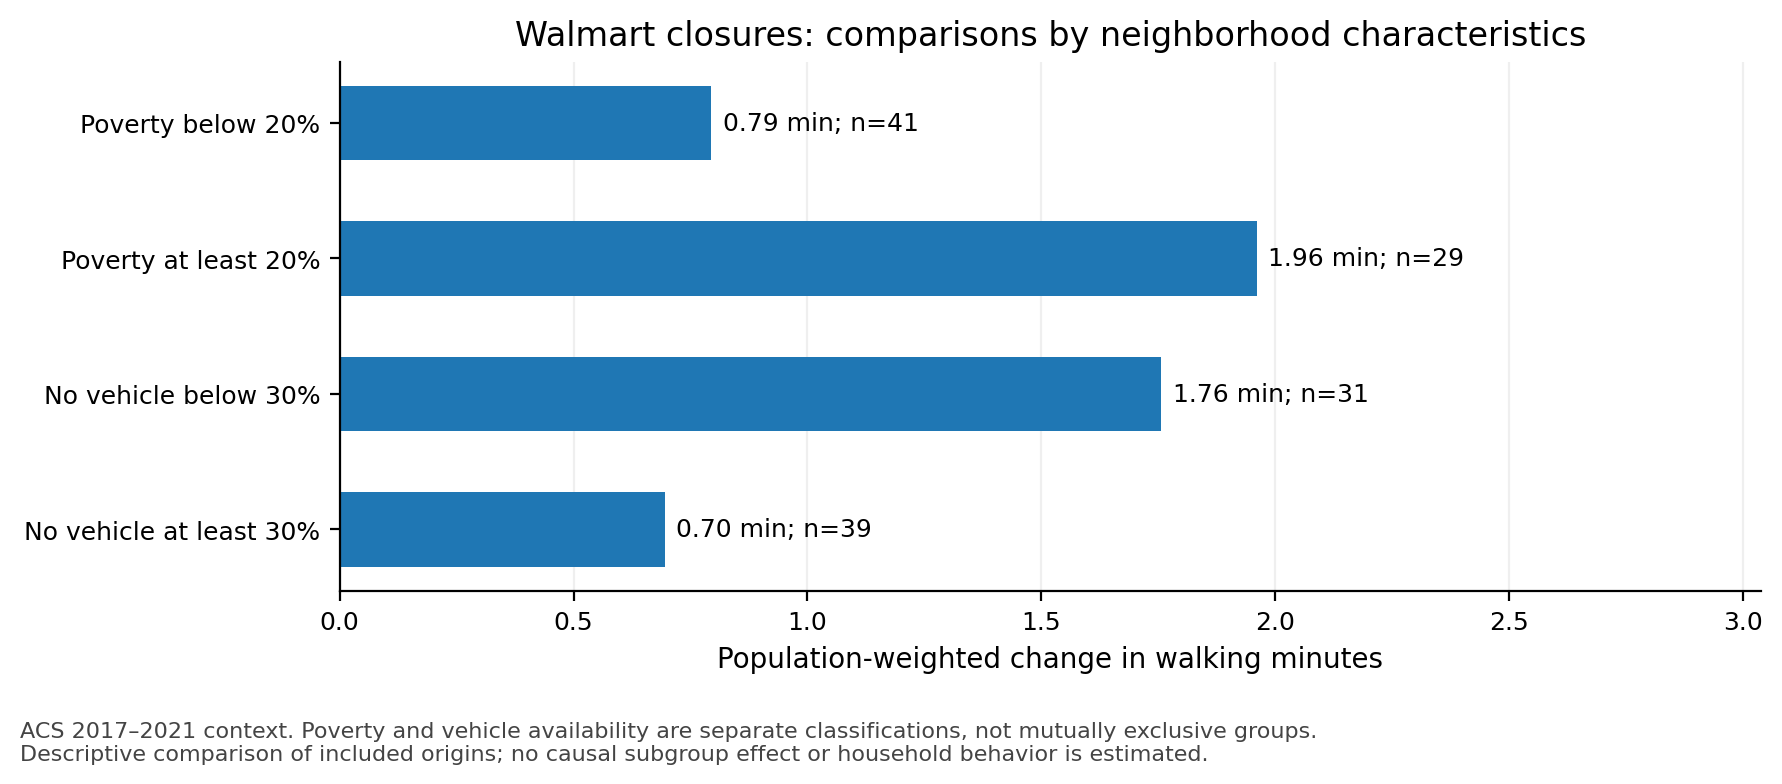

In [6]:
display(pd.read_csv(DATA/'equity_comparisons.csv'))
display(pd.read_csv(DATA/'access_sensitivity.csv'))
display(pd.Series(summary['alternate_chatham_coordinate']))
display(Image(filename=str(FIG/'09_equity_comparison.png')))

## 6. Conditional emissions
The scenario uses 1,000 dedicated round trips and an illustrative 400 g CO₂/mile factor. Walking and driving shares are assumptions; route changes are not multiplied by the full tract population.

,period,assumed_car_share,assumed_round_trips,additional_travel_share,tailpipe_co2_change_kg
0,whole_foods_closure,0.00,1000,1.0,0.000000
1,whole_foods_closure,0.25,1000,1.0,21.487283
2,whole_foods_closure,0.50,1000,1.0,42.974565
3,whole_foods_closure,0.75,1000,1.0,64.461848
4,whole_foods_closure,1.00,1000,1.0,85.949130
5,walmart_closures,0.00,1000,1.0,0.000000
6,walmart_closures,0.25,1000,1.0,13.417493
7,walmart_closures,0.50,1000,1.0,26.834987
8,walmart_closures,0.75,1000,1.0,40.252480
9,walmart_closures,1.00,1000,1.0,53.669974


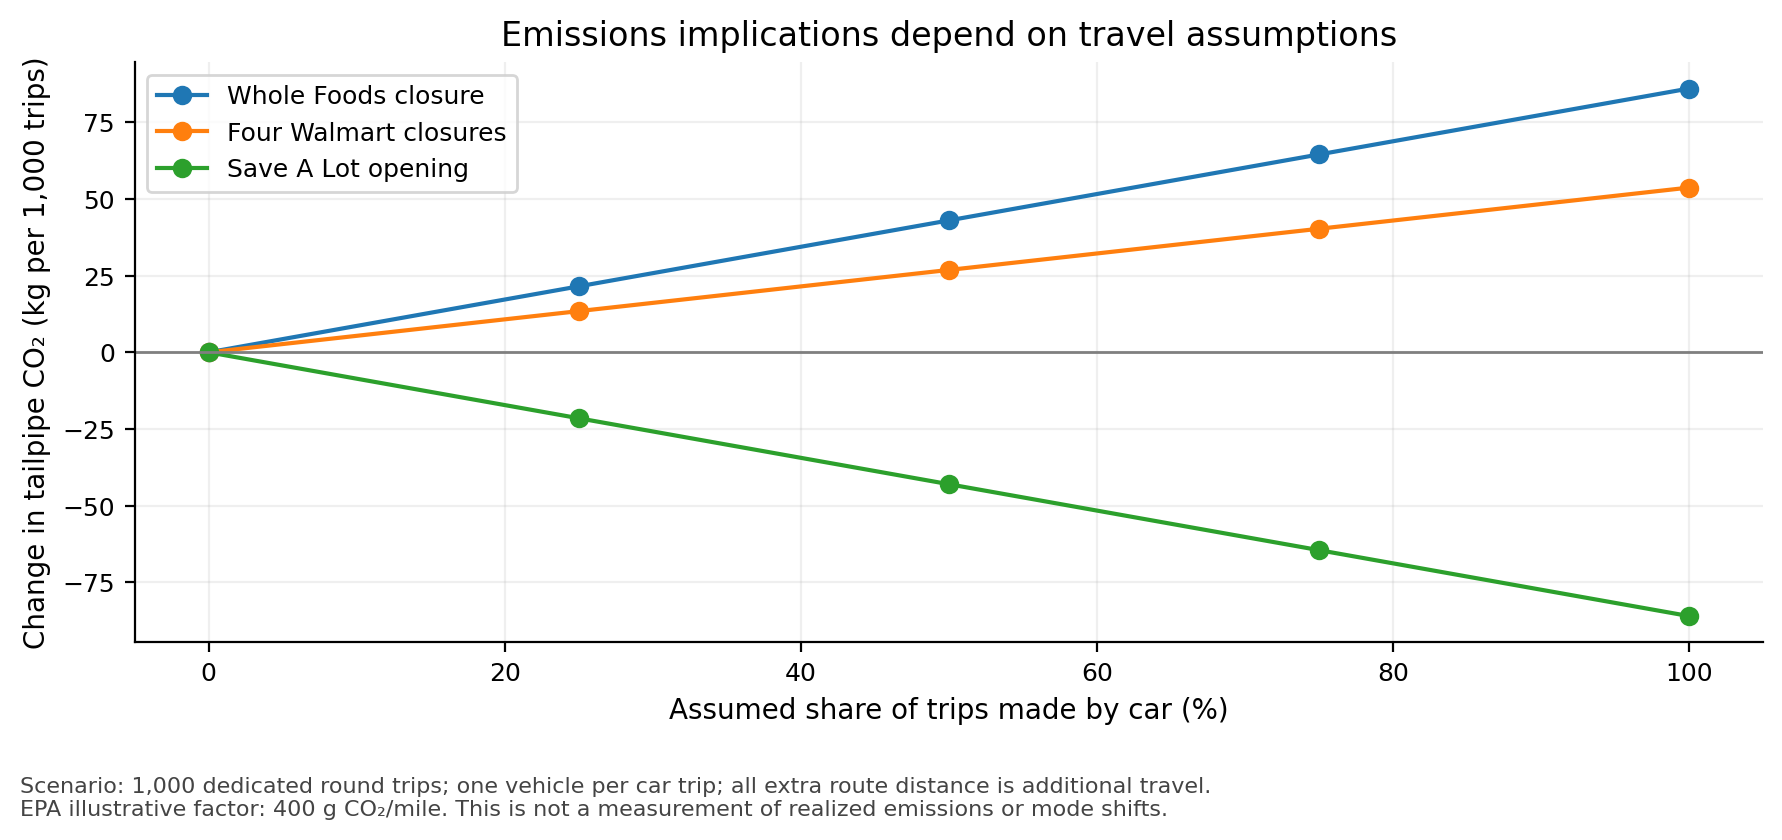

In [7]:
from src.analysis import conditional_co2
scenario = pd.read_csv(DATA/'emissions_scenarios.csv')
display(scenario)
assert conditional_co2(1.609344,1,trips=1) == 0.4
display(Image(filename=str(FIG/'10_emissions_sensitivity.png')))

## Discussion
Closure effects on nearest-outlet access vary with the remaining grocery network. Reopening the Englewood address restores the location-based measure under these assumptions. That does not establish equivalent products, prices, customer return or emissions. Actual behavior requires the licensed panel described in notebook 03.